In [70]:
%matplotlib inline

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import stft, resample_poly
from ipywidgets import VBox, HBox, FloatSlider, Output, Label, Dropdown, FloatLogSlider
from IPython.display import display, clear_output, Audio
from scipy.signal import butter, sosfiltfilt


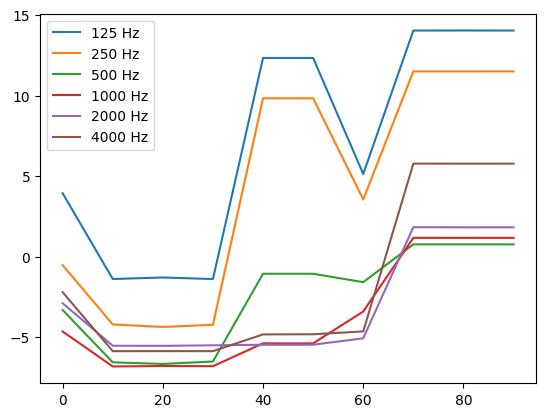

In [76]:

meas = [
    ["../samples/deg1.wav", [10, 0, 20, 30]],
    ["../samples/deg0.wav", [0, 0, 0, 0, 0]],
    ["../samples/deg2.wav", [90, 80, 70, 70, 70, 70]],
    ["../samples/deg3.wav", [60]],
    ["../samples/deg4.wav", [40, 40]],
    ["../samples/deg4.wav", [50]],
    ]

def moving_average(a, n=3):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def filter_into_octave_bands(signal, fs, centers=None, order=4):
    """
    Filter a 1D signal into 1-octave bands using zero-phase Butterworth bandpass filters.

    Parameters
    ----------
    signal : array_like
        1D array of audio samples.
    fs : float
        Sampling rate in Hz.
    centers : sequence of float, optional
        Center frequencies (Hz) for octave bands. Defaults to ANSI nominal centers.
    order : int, optional
        Filter order per band edge (Butterworth). Default 4 (total 8th-order bandpass).

    Returns
    -------
    dict
        Mapping {center_frequency_hz: filtered_signal_ndarray}.
        Bands that cannot be realized (outside Nyquist or below DC) are omitted.
    """
    x = np.asarray(signal, dtype=float)
    nyq = fs * 0.5
    if centers is None:
        centers = np.array([125, 250, 500, 1000, 2000, 4000])

    bands = {}
    k = np.sqrt(2.0)  # octave band ratio
    for fc in centers:
        fl = fc / k
        fh = fc * k

        # Skip bands that cannot be represented
        if fh <= 0 or fl >= nyq:
            continue

        # Clamp to valid range with a small margin from 0 and Nyquist
        fl_clamped = max(fl, 1e-6)
        fh_clamped = min(fh, nyq * 0.999)

        if fl_clamped >= fh_clamped:
            continue

        sos = butter(order, [fl_clamped / nyq, fh_clamped / nyq], btype="bandpass", output="sos")
        y = sosfiltfilt(sos, x)
        bands[int(fc)] = y

    return bands

def spl_db(signal, ref_pressure=20e-6, calibration=1.0):
    """
    Compute broadband Sound Pressure Level (SPL) in dB from a 1D NumPy array.

    Parameters
    ----------
    signal : np.ndarray
        1D array of audio samples. If samples are already in Pascals, use calibration=1.0.
        If samples are in arbitrary units (e.g., PCM counts), provide a calibration factor
        in Pa per unit.
    ref_pressure : float, optional
        Reference pressure in Pascals. Default is 20 µPa (20e-6), the standard for air.
    calibration : float, optional
        Scale factor (Pa per unit) to convert `signal` units to Pascals. Default 1.0.

    Returns
    -------
    float
        SPL in dB re 20 µPa.
    """
    # Convert to Pascals via calibration
    p = np.asarray(signal, dtype=float) * calibration
    # RMS pressure
    rms = np.sqrt(np.mean(p**2))
    # Avoid log of zero
    if rms <= 0 or not np.isfinite(rms):
        return float("-inf")
    return 20.0 * np.log10(rms / ref_pressure)

fc = np.array([125, 250, 500, 1000, 2000, 4000])
results = {}

for ppp in meas:
    path, angles = ppp
    data, sr = sf.read(path, always_2d=True)
    x = data[:, 0]

    f = 5000
    marker = np.exp(np.arange(sr)*f/sr*2j*np.pi) / sr

    N = 1
    while N < x.shape[0]+sr:
        N *= 2

    a = np.zeros(N, dtype=np.complex64)
    b = np.zeros(N, dtype=np.complex64)

    a[:x.shape[0]] = x
    b[:sr] = marker

    y = np.abs(np.fft.ifft(np.fft.fft(a)*np.fft.fft(b)))
    y = moving_average(y, sr)

    peaks = []
    ma = np.max(y)
    for i in range(1, len(y)-1):
        if y[i] > y[i-1] and y[i] > y[i+1] and y[i] > 0.2 * ma:
            if len(peaks) > 0 and i-peaks[-1] < sr:
                continue
            peaks.append(i)

    for i in range(len(angles)):
        bands = filter_into_octave_bands(x[i+sr:i+sr*2], sr, fc)
        for k, v in bands.items():
            bands[k] = spl_db(v)
        results[angles[i]] = bands


angles = [*results.keys()]
angles = sorted(angles)
values = []
for i in angles:
    spl = []
    for k, v in results[i].items():
        spl.append(v)
    values.append(spl)

angles = np.array(angles)
values = np.array(values).T

for i in range(len(fc)):
    plt.plot(angles, values[i], label=f"{fc[i]} Hz")

plt.legend()